# Cells that crossed the junction line

**The question.** Each assembloid is two organoids fused together; each organoid carries its own label, so each channel (AF555, AF488) is **at home** in one of them. A cell positive for a channel that sits on the *other* side of the junction line has **crossed** — it migrated from its home organoid into the other one. How many cross, how far do they go, do they travel along the tissue surface, and does any of it differ between genotypes (WT3 against GD1)? AF488 is the label of main interest.

**How.** Every cell of each annotated section was segmented once (Cellpose, nuclear channel AF405) and measured (`count_cells.py`); `count_common.py` gives each cell its signed distance from the junction line and its distance to the tissue edge. Nothing is segmented here.

- **Which side is home** is read from the data, per sample and channel: the side of the line where that channel's cells are brighter (median). Cells beyond either end of the line have no side and are left out.
- **Crossed** = positive cells on the side where the channel is *not* at home, more than a small gap past the line (the line is drawn by hand, so the first few µm are uncertain), counted within 50, 100 and 300 µm of the line and at any distance. Divided by the length of the line in mm: **crossed per mm of junction**.
- **The line**: the first annotator's (`first`), the main one; the second annotator's (`second`, Quillan's) as a check: a result that changes with who drew the line is not to be trusted.

**Four rules for "positive"** (the same as in `counts_in_band`):

| short name | rule |
|---|---|
| band +3 SD | above median + 3 SD of the band's cells (what the junction analysis does now) |
| band +7 SD, filtered | the same at 7 SD, after subtracting the local median (45 µm), which removes slow haze |
| negative 99.9th pct | above the 99.9th percentile of the **negative control**: cells deep (> 300 µm) in the organoid where the channel is not at home, away from the tissue edge |
| ring contrast, no autofl. | brighter than its own surrounding ring by more than 99 % of the negative control cells are, and not as bright (for its ring) in the other channel (autofluorescence) |

Note that the negative control lies in the very region where crossed cells are counted (beyond 300 µm). Its 99.9th percentile tolerates a few migrants there, but a sample with many far-travelling migrants raises its own bar under the two negative-control rules.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import count_common as C

warnings.filterwarnings("ignore", category=RuntimeWarning)       # medians of empty groups, small-n tests
pd.set_option("display.width", 200)

cells, meta = C.load_all()
LABEL = C.label_channel(meta)
CHANNELS = list(meta["channels"].iloc[0])
LINES = [b for b in ("first", "second") if meta["bands"].apply(lambda x: b in x).any()]

# The four positivity rules compared, with short names for tables and figures.
RULE_NAMES = {
    "band median + 3 SD (current)": "band +3 SD",
    "band median + 7 SD, median filter": "band +7 SD, filtered",
    "negative control 99.9th pct": "negative 99.9th pct",
    "ring contrast > negative 99th pct, no autofluorescence": "ring contrast, no autofl.",
}
RULES = {ch: {RULE_NAMES[k]: f for k, f in C.rules(CHANNELS, ch).items() if k in RULE_NAMES} for ch in CHANNELS}
SHORT_RULES = list(RULE_NAMES.values())
GENOTYPE_COLOURS = {"WT3": "tab:blue", "GD1": "tab:orange", "WT2": "tab:green"}



def tidy(table, digits=2):
    """Round the numeric columns of a table that mixes numbers and text (compare_groups)."""
    table = table.copy()
    for c in table.columns:
        values = pd.to_numeric(table[c], errors="coerce")
        if values.notna().sum() == table[c].notna().sum():
            table[c] = values.round(digits)
    return table


print(f"label channel: {LABEL}; channels: {CHANNELS}; lines: {LINES}")
design = meta[["Genotype", "Experiment", "slide"]].copy()
design.index = [C.short(n) for n in design.index]
print("samples per genotype and experiment:")
display(pd.crosstab(design["Genotype"], design["Experiment"], margins=True))

print(f"gap left out past the line: {C.GAP_UM:g} µm")

30 of 30 annotated samples measured, 919,868 cells; bands: first 30, second 27, automatic 26
label channel: AF488; channels: ['AF555', 'AF488']; lines: ['first', 'second']
samples per genotype and experiment:


Experiment,8,9,10,All
Genotype,,,,
GD1,5,6,8,19
WT3,2,3,6,11
All,7,9,14,30


gap left out past the line: 2 µm


## 1. Counting

For each sample, line, channel and rule: the positive cells, the crossed ones within each distance, their **away distance** (how far past the line, into the organoid where the channel is not at home) and their distance to the tissue edge. Also the profile of § 3.

In [2]:
TOPS = {"≤ 50 µm": 50, "≤ 100 µm": 100, "≤ 300 µm": 300, "any distance": None}
BINS = np.arange(-600, 601, 25)
MIN_BIN_CELLS = 20          # profile points from fewer cells are left out
MIN_DEPTH_CELLS = 5         # migration depth only from at least this many crossed cells

homes, rows, profile_rows, edge_store = [], [], [], {}
for name, df in cells.items():
    info = meta.loc[name, ["Genotype", "Experiment", "slide"]].to_dict()
    for line in LINES:
        if f"in {line}" not in df:
            continue
        beside = df[f"beside {line}"].to_numpy()
        length_mm = meta.loc[name, "lengths (um)"][line] / 1000
        edge = df["edge (um)"].to_numpy()
        for ch in CHANNELS:
            away = C.away_distance(df, ch, line)
            homes.append({"name": name, "sample": C.short(name), "line": line, "channel": ch,
                          "home on the band's side": C.home_is_band_side(df, ch, line), **info})
            which = np.digitize(away, BINS)
            in_range = beside & (which >= 1) & (which < len(BINS))
            within_300 = C.region(df, "crossed", line, ch, 300)
            for rule, f in RULES[ch].items():
                pos = np.asarray(f(df, line), bool)
                row = {"name": name, "sample": C.short(name), "line": line, "channel": ch, "rule": rule,
                       "junction (mm)": length_mm, **info}
                for key, top in TOPS.items():
                    k = int((pos & C.region(df, "crossed", line, ch, top)).sum())
                    row[f"crossed {key}"] = k
                    row[f"crossed {key}, per mm"] = k / length_mm if length_mm else np.nan
                depth = away[pos & C.region(df, "crossed", line, ch, None)]
                enough = len(depth) >= MIN_DEPTH_CELLS
                row["depth, median (µm)"] = np.median(depth) if enough else np.nan
                row["depth, 90th pct (µm)"] = np.percentile(depth, 90) if enough else np.nan
                rows.append(row)
                g = pd.DataFrame({"bin": which[in_range], "pos": pos[in_range]}).groupby("bin")["pos"].agg(["size", "mean"])
                for b, (n, m) in g.iterrows():
                    if n >= MIN_BIN_CELLS:
                        profile_rows.append({"sample": C.short(name), "line": line, "channel": ch, "rule": rule,
                                             "distance": BINS[b - 1] + 12.5, "% positive": 100 * m})
                if line == "first":
                    edge_store[(name, ch, rule)] = (edge[within_300 & pos], edge[within_300])
homes, crossed, profiles = pd.DataFrame(homes), pd.DataFrame(rows), pd.DataFrame(profile_rows)
print(f"{crossed['sample'].nunique()} samples, {len(crossed)} counts")

30 samples, 456 counts


## 2. Which side is each channel's home?

`True` = the channel's cells are brighter on the side the band reaches into. If the two channels mark the two organoids, their homes should be on **opposite** sides. The band analysis (`counts_in_band`) assumes the band reaches into the organoid where **AF488 is not at home** (AF488 home = `False`), so that AF488-positive cells in the band are migrants; the last columns say whether that holds.

In [3]:
h = homes.pivot_table(index=["Genotype", "sample"], columns=["line", "channel"], values="home on the band's side",
                      aggfunc="first")
for line in LINES:
    if (line, LABEL) in h:
        others = [c for c in CHANNELS if c != LABEL and (line, c) in h]
        if others:
            h[(line, "opposite sides")] = h[(line, LABEL)] != h[(line, others[0])]
        h[(line, f"band in {LABEL}'s away organoid")] = ~h[(line, LABEL)].astype(bool)
h = h.sort_index(axis=1, level=0, sort_remaining=False)
display(h)
print("samples where it holds, out of", len(h), ":", {f"{a}: {b}": int(h[(a, b)].sum()) for a, b in h.columns
                                                      if b in ("opposite sides", f"band in {LABEL}'s away organoid")})

line                  first                                                     second                                                    
channel               AF488  AF555 opposite sides band in AF488's away organoid  AF488  AF555 opposite sides band in AF488's away organoid
Genotype sample                                                                                                                           
GD1      039-038_s5   False   True           True                          True  False   True           True                          True
         041-040_s1   False   True           True                          True  False   True           True                          True
         041-040_s16  False   True           True                          True  False   True           True                          True
         041-040_s26  False   True           True                          True  False   True           True                          True
         044-043_s19  False   True           True                          True    NaN    NaN           True                         False
         045-044_s15  False   True           True                          True  False   True           True                          True
         045-044_s16  False   True           True                          True  False   True           True                          True
         045-044_s4   False   True           True                          True  False   True           True                          True
         048-047_s6   False   True           True                          True  False   True           True                          True
         050-049_s5   False   True           True                          True  False   True           True                          True
         051-050_s12  False   True           True                          True    NaN    NaN           True                         False
         052-051_s14  False   True           True                          True  False   True           True                          True
         052-051_s18  False   True           True                          True  False   True           True                          True
         052-051_s23  False  False          False                          True    NaN    NaN           True                         False
         053-052_s5   False   True           True                          True  False   True           True                          True
         054-053_s7   False   True           True                          True  False   True           True                          True
         055-054_s15  False   True           True                          True  False   True           True                          True
         055-054_s23  False   True           True                          True  False   True           True                          True
         055-054_s24  False   True           True                          True  False   True           True                          True
WT3      019-018_s10  False   True           True                          True  False   True           True                          True
         020-019_s4   False   True           True                          True  False   True           True                          True
         026-025_s4   False   True           True                          True  False   True           True                          True
         026-025_s8   False   True           True                          True  False   True           True                          True
         027-026_s5   False  False          False                          True  False  False          False                          True
         031-030_s7   False   True           True                          True  False   True           True                          True
         033-032_s12  False   True           True                          True  False   True           True

samples where it holds, out of 30 : {'first: opposite sides': 28, "first: band in AF488's away organoid": 30, 'second: opposite sides': 29, "second: band in AF488's away organoid": 27}


## 3. Profile across the line

The % of positive cells at each distance from the line, in 25 µm bins from −600 to +600 µm, **oriented so that the channel's home is on the left** (negative distances) and the other organoid on the right. Only cells beside the line; bins with fewer than 20 cells are left out. Grey lines: one per sample; black: the median over samples. One panel per rule; top row AF488, bottom row AF555; first annotator's line.

**How to read it.** High on the left, a drop at 0: the line is where the label changes. What stays above the floor on the right is migration — how high and how far out it reaches. A rule whose right-hand side is flat at its floor finds no migrants beyond background; a slow decay over the first 100–300 µm is what migrating cells look like. Log scale (symlog: zero drawn at the bottom).

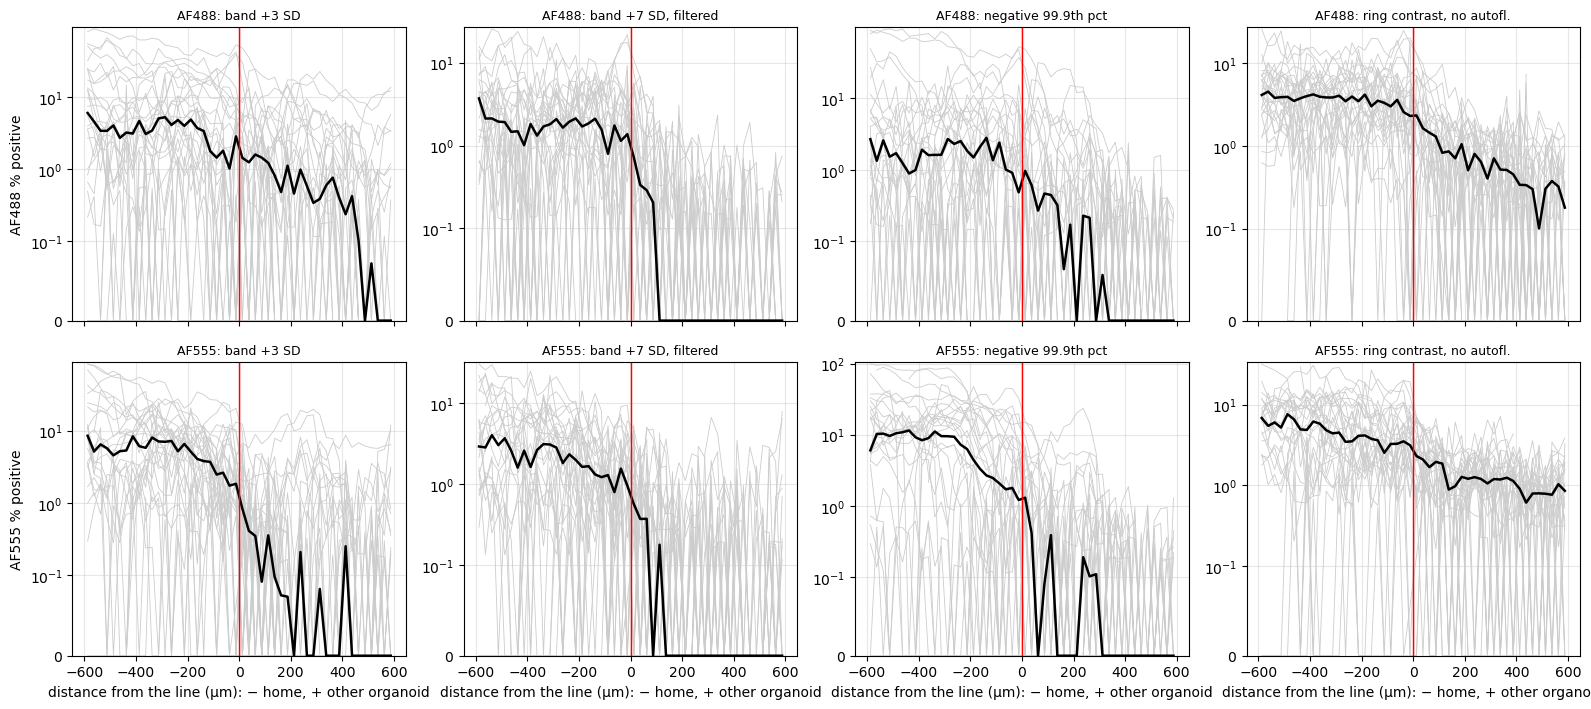

In [4]:
order = [LABEL] + [c for c in CHANNELS if c != LABEL]
fig, axes = plt.subplots(len(order), len(SHORT_RULES), figsize=(4 * len(SHORT_RULES), 3.6 * len(order)),
                         sharex=True, squeeze=False)
for r, ch in enumerate(order):
    for ax, rule in zip(axes[r], SHORT_RULES):
        p = profiles[(profiles.channel == ch) & (profiles.rule == rule) & (profiles.line == "first")]
        for s, g in p.groupby("sample"):
            ax.plot(g["distance"], g["% positive"], color="0.8", lw=0.6)
        m = p.groupby("distance")["% positive"].median()
        ax.plot(m.index, m.values, color="black", lw=1.8)
        ax.axvline(0, color="red", lw=1)
        ax.axvspan(-C.GAP_UM, C.GAP_UM, color="red", alpha=0.08)
        ax.set_yscale("symlog", linthresh=0.1); ax.set_ylim(bottom=0); ax.grid(alpha=0.3)
        ax.set_title(f"{ch}: {rule}", fontsize=9)
        if r == len(order) - 1:
            ax.set_xlabel("distance from the line (µm): − home, + other organoid")
    axes[r, 0].set_ylabel(f"{ch} % positive")
plt.tight_layout()

## 4. How many crossed

Per sample, AF488 with the first annotator's line: crossed cells **per mm of junction**, within 50, 100 and 300 µm of the line and at any distance, under each rule. The counts are cumulative (≤ 100 µm includes ≤ 50 µm). Then the medians over samples for both channels and both lines.

In [5]:
main = crossed[(crossed.line == "first") & (crossed.channel == LABEL)]
per_mm = [f"crossed {k}, per mm" for k in TOPS]
t = main.pivot_table(index=["Genotype", "sample"], columns="rule", values=per_mm, sort=False)
t = t.reorder_levels([1, 0], axis=1)[[(r, c) for r in SHORT_RULES for c in per_mm]]
t.columns = pd.MultiIndex.from_tuples([(r, c.replace("crossed ", "").replace(", per mm", "")) for r, c in t.columns])
print(f"{LABEL} crossed per mm of junction, first line:")
t.sort_index().round(1)

AF488 crossed per mm of junction, first line:


band +3 SD                                band +7 SD, filtered                                negative 99.9th pct                                ring contrast, no autofl.  \
                        ≤ 50 µm ≤ 100 µm ≤ 300 µm any distance              ≤ 50 µm ≤ 100 µm ≤ 300 µm any distance             ≤ 50 µm ≤ 100 µm ≤ 300 µm any distance                   ≤ 50 µm   
Genotype sample                                                                                                                                                                                   
GD1      039-038_s5        42.7     52.2     58.9         96.9                 25.6     28.5     32.3         38.9                19.9     21.8     22.8         29.4                      26.6   
         041-040_s1        60.8    162.2    402.4        555.3                  1.6      3.1     10.9         17.2                48.4    113.9    171.6        179.4                       7.8   
         041-040_s16       25.1     82.9    144.3        161.1                  0.0      0.0      0.0          0.0                22.3     71.7    122.0        126.6                       3.7   
         041-040_s26        9.8     16.3     66.1        107.8                  0.8      0.8      5.7          6.5                 2.4      3.3     10.6         13.9                       4.1   
         044-043_s19        0.0      0.0      0.0          0.0                  0.0      0.0      0.0          0.0                 0.0      0.0      1.5          3.0                       1.5   
         045-044_s15       23.3     48.8     55.3         58.2                  2.2      4.4      6.6          7.3                37.9     76.4     85.9         89.5                      13.1   
         045-044_s16        0.0      0.0      0.0          0.0                  0.0      0.0      0.0          0.0                 0.0      0.0      0.0          2.5                       2.5   
         045-044_s4         0.0     15.5     38.7         38.7                  0.0     20.7     31.0         31.0                23.2    232.3    663.4        668.6                       0.0   
         048-047_s6         4.8      7.6     88.3        210.3                  9.0     14.5     20.7         29.7                 4.8      7.6     22.8         40.7                      16.6   
         050-049_s5         1.5      5.8     20.5         26.3                  1.5      1.5      2.9          5.8                 1.5      5.8     14.6         19.0                       4.4   
         051-050_s12       36.9     57.5     87.2         88.2                 22.6     34.9     53.3         56.4                19.5     31.8     45.1         46.2                       7.2   
         052-051_s14        7.7      7.7    433.7        850.2                  4.3      4.3      6.0         13.7                 0.0      0.0      0.0          8.6                       6.0   
         052-051_s18        3.9      5.2     18.3         18.3                  6.6      6.6     21.0         22.3                13.1     70.8    222.8        226.7                      23.6   
         052-051_s23        0.0      0.0      0.0          0.0                  0.0      0.0      0.0          0.0                 0.0      0.0      0.0          8.0                       2.7   
         053-052_s5         0.0     17.0    234.0        291.9                  0.8      1.5     10.0         10.8                 0.0      3.1     62.5         71.0                       4.6   
         054-053_s7         0.8     69.8    397.2        679.0                  0.8      2.5      5.9          7.6                 0.0      0.0     49.6         58.1                       0.8   
         055-054_s15        1.7      5.8     51.7         73.5                  3.3      4.2      5.8          5.8                 1.7      2.5     10.9         15.0                      13.4   
         055-054_s23        0.0     14.7     98.6        122.3                  0.0      0.0      5.6          9.8       

In [6]:
counts_cols = [f"crossed {k}" for k in TOPS]
summary = crossed.groupby(["channel", "line", "rule"], sort=False)[counts_cols + per_mm].median()
summary.columns = [c.replace("crossed ", "") for c in summary.columns]
print("median over samples (counts, then per mm of junction):")
summary.reindex(order, level="channel").round(1)

median over samples (counts, then per mm of junction):


≤ 50 µm  ≤ 100 µm  ≤ 300 µm  any distance  ≤ 50 µm, per mm  ≤ 100 µm, per mm  ≤ 300 µm, per mm  any distance, per mm
channel line   rule                                                                                                                                           
AF488   first  band +3 SD                    11.0      27.0      95.0         165.5             11.4              24.0              79.6                 115.0
               band +7 SD, filtered           3.5       5.5      10.5          14.0              3.2               6.2              11.1                  15.4
               negative 99.9th pct            5.5       7.0      32.5          46.5              4.8               6.7              22.8                  36.1
               ring contrast, no autofl.     13.5      29.5      50.5          70.0              9.7              22.1              45.4                  67.0
        second band +3 SD                     7.0      23.0     127.0         179.0              6.0              17.3              81.5                 125.1
               band +7 SD, filtered           2.0       6.0      11.0          15.0              1.9               6.7               9.4                  16.6
               negative 99.9th pct            4.0       8.0      38.0          49.0              4.5               7.8              30.9                  48.4
               ring contrast, no autofl.     10.0      22.0      68.0          80.0              8.6              22.7              49.0                  71.8
AF555   first  band +3 SD                     3.5       6.0      20.5          40.0              3.8               6.1              20.0                  37.5
               band +7 SD, filtered           2.5       6.0      14.5          26.5              3.4               6.0              12.0                  24.3
               negative 99.9th pct            4.0       5.5      13.5          26.5              4.7               6.4              14.2                  26.7
               ring contrast, no autofl.      8.5      17.0      59.5         166.0             10.1              21.5              61.5                 156.7
        second band +3 SD                     2.0       5.0      17.0          33.0              1.9               5.5              12.4                  30.1
               band +7 SD, filtered           2.0       5.0      12.0          25.0              2.2               5.8               9.5                  23.1
               negative 99.9th pct            4.0       7.0      12.0          26.0              2.6               5.3              10.6                  22.4
               ring contrast, no autofl.     15.0      23.0      69.0         179.0             12.4              23.4              56.7                 166.6

## 5. How far they go

For the crossed positive cells at any distance: the **median** and the **90th percentile** of how far past the line they are (µm). The median says where a typical migrant sits; the 90th percentile how far the furthest tenth reach. Not computed for a sample with fewer than 5 crossed cells. Per sample for AF488 (first line), then medians over samples.

In [7]:
depth_cols = ["depth, median (µm)", "depth, 90th pct (µm)"]
d = main.set_index(["Genotype", "sample", "rule"])[depth_cols].unstack("rule")
d = d.reorder_levels([1, 0], axis=1)[[(r, c) for r in SHORT_RULES for c in depth_cols]]
display(d.sort_index().round(0))
print("median over samples:")
crossed.groupby(["channel", "line", "rule"], sort=False)[depth_cols].median().reindex(order, level="channel").round(0)

rule                         band +3 SD                      band +7 SD, filtered                      negative 99.9th pct                      ring contrast, no autofl.                     
                     depth, median (µm) depth, 90th pct (µm)   depth, median (µm) depth, 90th pct (µm)  depth, median (µm) depth, 90th pct (µm)        depth, median (µm) depth, 90th pct (µm)
Genotype sample                                                                                                                                                                               
GD1      039-038_s5                64.0                432.0                 27.0                351.0                36.0                431.0                      51.0                450.0
         041-040_s1               160.0                607.0                187.0                440.0                81.0                186.0                     408.0                792.0
         041-040_s16               97.0                300.0                  NaN                  NaN                87.0                226.0                     221.0                519.0
         041-040_s26              261.0                432.0                265.0                303.0               265.0                336.0                     177.0                335.0
         044-043_s19                NaN                  NaN                  NaN                  NaN                 NaN                  NaN                     268.0                378.0
         045-044_s15               56.0                126.0                 92.0                208.0                55.0                109.0                     123.0                364.0
         045-044_s16                NaN                  NaN                  NaN                  NaN                 NaN                  NaN                     285.0                441.0
         045-044_s4               139.0                154.0                 78.0                151.0               136.0                226.0                     201.0                416.0
         048-047_s6               313.0                466.0                136.0               1241.0               293.0                472.0                     224.0                986.0
         050-049_s5               148.0                331.0                  NaN                  NaN               108.0                326.0                     197.0                407.0
         051-050_s12               69.0                219.0                 74.0                240.0                65.0                207.0                      73.0                315.0
         052-051_s14              298.0                497.0                379.0                588.0               379.0                560.0                     450.0                759.0
         052-051_s18              213.0                243.0                201.0                247.0               139.0                233.0                     142.0                343.0
         052-051_s23                NaN                  NaN                  NaN                  NaN                 NaN                  NaN                     319.0                520.0
         053-052_s5               201.0                337.0                143.0                218.0               208.0                302.0                     257.0                549.0
         054-053_s7               259.0                667.0                133.0                572.0               250.0                309.0                     343.0                679.0
         055-054_s15              156.0                644.0                 39.0                195.0               168.0                648.0                     117.0                371.0
         055-054_s23              134.0                483.0                250.0                562.0               169.0                542.0                     262.0           

median over samples:


depth, median (µm)  depth, 90th pct (µm)
channel line   rule                                                               
AF488   first  band +3 SD                              158.0                 432.0
               band +7 SD, filtered                    112.0                 327.0
               negative 99.9th pct                     162.0                 336.0
               ring contrast, no autofl.               200.0                 520.0
        second band +3 SD                              166.0                 375.0
               band +7 SD, filtered                    105.0                 374.0
               negative 99.9th pct                     145.0                 348.0
               ring contrast, no autofl.               186.0                 566.0
AF555   first  band +3 SD                              273.0                 627.0
               band +7 SD, filtered                    259.0                 639.0
               negative 99.9th pct                     218.0                 511.0
               ring contrast, no autofl.               302.0                 769.0
        second band +3 SD                              335.0                 663.0
               band +7 SD, filtered                    266.0                 710.0
               negative 99.9th pct                     249.0                 612.0
               ring contrast, no autofl.               386.0                 835.0

## 6. Do crossed cells travel along the surface?

If migrants move along the outside of the tissue, crossed positive cells should sit **closer to the tissue edge** than the cells around them. Fair comparison: the crossed AF488-positive cells within 300 µm of the line, against **all cells on the same side within the same 300 µm**, by their distance to the tissue edge (first line).

- **Figure:** cumulative distributions, pooled over samples. A curve that rises earlier (left) means closer to the edge.
- **Table:** median edge distance of each group (pooled), the pooled Mann-Whitney p (cells are not independent — they come from a few samples — so this p is optimistic), and the per-sample view: median over samples of (median edge distance of crossed positives − that of all cells), and in how many samples the crossed cells are closer. Samples with fewer than 5 crossed cells are left out of the per-sample view. The Wilcoxon signed-rank p on the per-sample differences is the honest test (needs at least 5 samples).

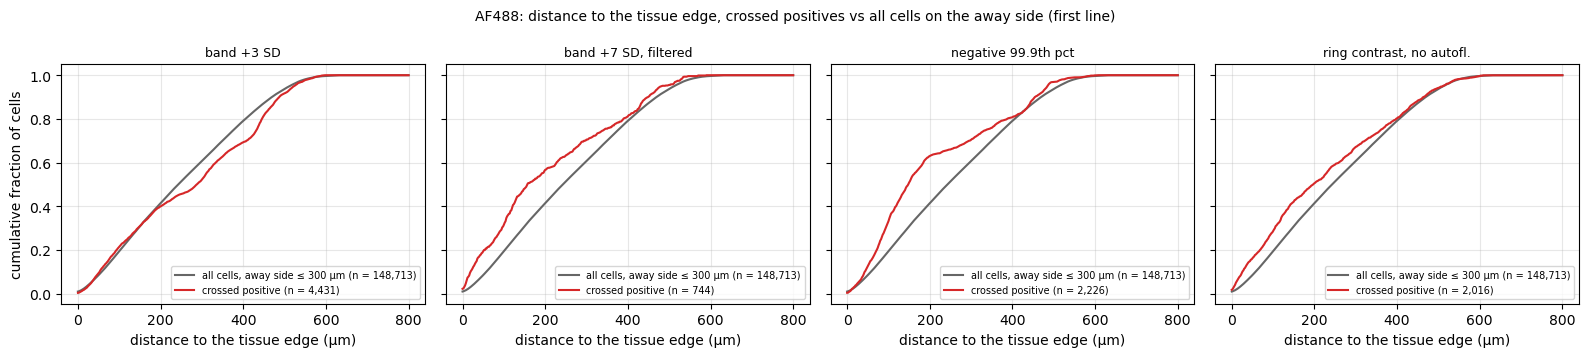

,"crossed positive, n","crossed positive, median edge (µm)","all away cells, median edge (µm)",pooled Mann-Whitney p,samples,"per sample: difference, median (µm)",samples where crossed are closer,Wilcoxon p (samples)
rule,,,,,,,,
band +3 SD,4431.0,287.126,242.267,0.0,26.0,-1.184,13.0,0.960
"band +7 SD, filtered",744.0,156.660,242.267,0.0,24.0,-46.563,17.0,0.034
negative 99.9th pct,2226.0,147.574,242.267,0.0,25.0,21.832,10.0,0.525
"ring contrast, no autofl.",2016.0,196.368,242.267,0.0,30.0,-20.195,19.0,0.253


In [8]:
fig, axes = plt.subplots(1, len(SHORT_RULES), figsize=(4 * len(SHORT_RULES), 3.6), sharey=True)
edge_rows = []
grid = np.linspace(0, 800, 401)
for ax, rule in zip(axes, SHORT_RULES):
    pos_all, ref_all, diffs = [], [], []
    for name in cells:
        if (name, LABEL, rule) not in edge_store:
            continue
        p, a = edge_store[(name, LABEL, rule)]
        pos_all.append(p); ref_all.append(a)
        if len(p) >= MIN_DEPTH_CELLS and len(a):
            diffs.append(np.median(p) - np.median(a))
    p, a = np.concatenate(pos_all), np.concatenate(ref_all)
    for values, label, colour in ((a, "all cells, away side ≤ 300 µm", "0.4"), (p, "crossed positive", "tab:red")):
        if len(values):
            ax.plot(grid, [np.mean(values <= g) for g in grid], color=colour, label=f"{label} (n = {len(values):,})")
    ax.set_title(rule, fontsize=9); ax.set_xlabel("distance to the tissue edge (µm)"); ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="lower right")
    diffs = np.asarray(diffs)
    edge_rows.append({"rule": rule, "crossed positive, n": len(p), "crossed positive, median edge (µm)": np.median(p) if len(p) else np.nan,
                      "all away cells, median edge (µm)": np.median(a) if len(a) else np.nan,
                      "pooled Mann-Whitney p": stats.mannwhitneyu(p, a).pvalue if len(p) and len(a) else np.nan,
                      "samples": len(diffs), "per sample: difference, median (µm)": np.median(diffs) if len(diffs) else np.nan,
                      "samples where crossed are closer": int((diffs < 0).sum()),
                      "Wilcoxon p (samples)": stats.wilcoxon(diffs).pvalue if len(diffs) >= 5 else np.nan})
axes[0].set_ylabel("cumulative fraction of cells")
fig.suptitle(f"{LABEL}: distance to the tissue edge, crossed positives vs all cells on the away side (first line)", fontsize=10)
plt.tight_layout()
plt.show()
pd.DataFrame(edge_rows).set_index("rule").astype(float).round(3)

## 7. Genotype

Per sample, AF488 with the first line: **crossed ≤ 300 µm per mm of junction** and the **median migration depth**, under each rule. `compare_groups` gives the median per genotype, their ratio, n per group and the Mann-Whitney p (two-sided); on samples, then on slide means (sections of one slide may be one assembloid, so the slide is the safer unit). Four rules are tested, so one p just under 0.05 is weak evidence. The figure shows each sample as a dot (marker = experiment) and the genotype median as a bar.

In [9]:
values = {"crossed ≤ 300 µm, per mm": "crossed ≤ 300 per mm", "depth, median (µm)": "depth median"}
per_sample = main.pivot_table(index="name", columns="rule", values=list(values), dropna=False)
per_sample.columns = [f"{values[v]} · {r}" for v, r in per_sample.columns]
per_sample = per_sample.join(meta[["Genotype", "Experiment", "slide"]])
columns = [f"{v} · {r}" for v in values.values() for r in SHORT_RULES]
print(f"genotypes: {per_sample['Genotype'].value_counts().to_dict()}; slides: "
      f"{per_sample.groupby('Genotype')['slide'].nunique().to_dict()}")
print("On samples:")
display(tidy(C.compare_groups(per_sample, columns, unit="sample"), 3))
print("On slide means:")
display(tidy(C.compare_groups(per_sample, columns, unit="slide"), 3))

genotypes: {'GD1': 19, 'WT3': 11}; slides: {'GD1': 11, 'WT3': 8}
On samples:


,GD1 median,WT3 median,n,WT3 / GD1,test,p
crossed ≤ 300 per mm · band +3 SD,66.127,80.275,19 vs 11,1.214,Mann-Whitney,0.547
"crossed ≤ 300 per mm · band +7 SD, filtered",5.890,20.749,19 vs 11,3.523,Mann-Whitney,0.002
crossed ≤ 300 per mm · negative 99.9th pct,22.757,27.799,19 vs 11,1.222,Mann-Whitney,0.547
"crossed ≤ 300 per mm · ring contrast, no autofl.",24.492,86.801,19 vs 11,3.544,Mann-Whitney,0.003
depth median · band +3 SD,157.892,160.441,16 vs 10,1.016,Mann-Whitney,0.895
"depth median · band +7 SD, filtered",136.369,82.210,13 vs 11,0.603,Mann-Whitney,0.451
depth median · negative 99.9th pct,153.058,162.301,16 vs 11,1.060,Mann-Whitney,0.863
"depth median · ring contrast, no autofl.",220.897,186.260,19 vs 11,0.843,Mann-Whitney,0.491


On slide means:


,GD1 median,WT3 median,n,WT3 / GD1,test,p
crossed ≤ 300 per mm · band +3 SD,88.268,128.222,11 vs 8,1.453,Mann-Whitney,0.778
"crossed ≤ 300 per mm · band +7 SD, filtered",8.985,24.108,11 vs 8,2.683,Mann-Whitney,0.026
crossed ≤ 300 per mm · negative 99.9th pct,45.140,20.476,11 vs 8,0.454,Mann-Whitney,0.600
"crossed ≤ 300 per mm · ring contrast, no autofl.",27.156,78.494,11 vs 8,2.890,Mann-Whitney,0.016
depth median · band +3 SD,166.207,190.550,10 vs 7,1.146,Mann-Whitney,0.962
"depth median · band +7 SD, filtered",136.369,87.046,9 vs 8,0.638,Mann-Whitney,0.606
depth median · negative 99.9th pct,162.919,147.175,10 vs 8,0.903,Mann-Whitney,0.897
"depth median · ring contrast, no autofl.",223.882,160.873,11 vs 8,0.719,Mann-Whitney,0.272


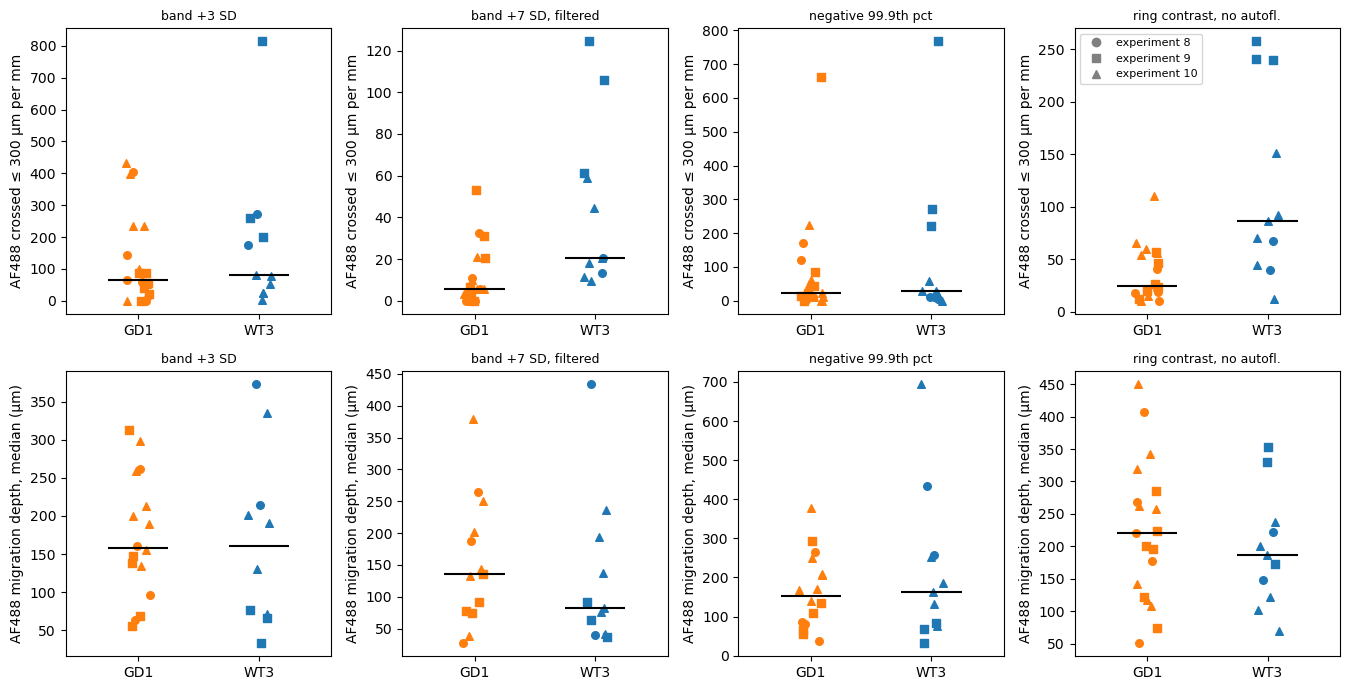

In [10]:
genotypes = sorted(per_sample["Genotype"].unique())
markers = dict(zip(sorted(per_sample["Experiment"].unique()), "os^Dv<>"))
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, len(SHORT_RULES), figsize=(3.4 * len(SHORT_RULES), 7))
for row, value in enumerate(values.values()):
    for ax, rule in zip(axes[row], SHORT_RULES):
        c = f"{value} · {rule}"
        for x, g in enumerate(genotypes):
            sub = per_sample[per_sample["Genotype"] == g]
            for e, s in sub.groupby("Experiment"):
                ax.scatter(x + rng.uniform(-0.1, 0.1, len(s)), s[c], marker=markers[e], s=30,
                           color=GENOTYPE_COLOURS.get(g, "grey"))
            ax.hlines(sub[c].median(), x - 0.25, x + 0.25, color="black")
        ax.set_xticks(range(len(genotypes)), genotypes); ax.set_xlim(-0.6, len(genotypes) - 0.4)
        ax.set_title(rule, fontsize=9)
        ax.set_ylabel(f"{LABEL} crossed ≤ 300 µm per mm" if row == 0 else f"{LABEL} migration depth, median (µm)")
handles = [plt.Line2D([], [], marker=m, ls="", color="grey", label=f"experiment {e}") for e, m in markers.items()]
axes[0, -1].legend(handles=handles, fontsize=8)
plt.tight_layout()

## 8. First against second line

Where both annotators drew a line, the crossed counts from each. **|second − first| / mean** is the typical relative difference (0.2 = they differ by 20 %); **CCC** (Lin's concordance) is 1 when they give identical counts per sample; Spearman says whether they rank the samples alike. CCC and Spearman need at least 3 samples. If the counts within 50 µm disagree much more than those within 300 µm, the exact position of the line matters most close to it — as expected, since a small shift of the line moves many cells across 50 µm.

In [11]:
if "second" in LINES:
    w = crossed.pivot_table(index=["sample", "channel", "rule"], columns="line", values=counts_cols)
    out = []
    for ch in order:
        for rule in SHORT_RULES:
            for key in counts_cols:
                if (key, "second") not in w:
                    continue
                g = w.xs((ch, rule), level=["channel", "rule"])[[(key, "first"), (key, "second")]].dropna()
                a, b = g[(key, "first")], g[(key, "second")]
                rel = ((b - a).abs() / ((a + b) / 2)).replace([np.inf, -np.inf], np.nan)
                out.append({"channel": ch, "rule": rule, "count": key.replace("crossed ", ""), "n": len(g),
                            "first (median)": a.median(), "second (median)": b.median(),
                            "|second − first| / mean (median)": rel.median(), "CCC": C.ccc(a, b),
                            "Spearman": stats.spearmanr(a, b).statistic if len(g) >= 3 else np.nan})
    display(pd.DataFrame(out).set_index(["channel", "rule", "count"]).round(2))
else:
    print("no second line drawn on the measured samples")

n  first (median)  second (median)  |second − first| / mean (median)   CCC  Spearman
channel rule                      count                                                                                              
AF488   band +3 SD                ≤ 50 µm       27            12.0              7.0                              0.61  0.96      0.85
                                  ≤ 100 µm      27            32.0             23.0                              0.16  0.97      0.90
                                  ≤ 300 µm      27           123.0            127.0                              0.08  0.99      0.97
                                  any distance  27           173.0            179.0                              0.07  0.96      0.96
        band +7 SD, filtered      ≤ 50 µm       27             4.0              2.0                              0.38  0.93      0.70
                                  ≤ 100 µm      27             6.0              6.0                              0.18  0.96      0.70
                                  ≤ 300 µm      27            12.0             11.0                              0.11  0.97      0.84
                                  any distance  27            14.0             15.0                              0.12  0.98      0.92
        negative 99.9th pct       ≤ 50 µm       27             6.0              4.0                              0.44  0.97      0.69
                                  ≤ 100 µm      27             8.0              8.0                              0.44  0.96      0.71
                                  ≤ 300 µm      27            33.0             38.0                              0.16  0.95      0.85
                                  any distance  27            51.0             49.0                              0.14  0.95      0.85
        ring contrast, no autofl. ≤ 50 µm       27            16.0             10.0                              0.50  0.94      0.77
                                  ≤ 100 µm      27            35.0             22.0                              0.22  0.95      0.81
                                  ≤ 300 µm      27            63.0             68.0                              0.11  0.97      0.91
                                  any distance  27            80.0             80.0                              0.10  0.99      0.94
AF555   band +3 SD                ≤ 50 µm       27             4.0              2.0                              0.61  0.65      0.68
                                  ≤ 100 µm      27             6.0              5.0                              0.40  0.81      0.86
                                  ≤ 300 µm      27            20.0             17.0                              0.14  0.99      0.89
                                  any distance  27            41.0             33.0                              0.14  0.99      0.97
        band +7 SD, filtered      ≤ 50 µm       27             4.0              2.0                              0.63  0.69      0.67
                                  ≤ 100 µm      27             6.0              5.0                              0.37  0.71      0.87
                                  ≤ 300 µm      27            14.0             12.0                              0.21  0.82      0.87
                                  any distance  27            27.0             25.0                              0.18  0.98      0.87
        negative 99.9th pct       ≤ 50 µm       27             6.0              4.0                              0.49  0.84      0.88
                                  ≤ 100 µm      27             7.0              7.0                              0.42  0.83      0.89
                                  ≤ 300 µm      27            15.0             12.0                              0.31  0.86      0.88
                                  any distance  27            29.0             26.0                              0.22  0.86      0.92
        ring contrast, no aut

### What it showed (21 October 2026: 30 samples)

**Orientation holds.** With the home side read from each channel's brightest cells, AF488 and AF555 are at home on opposite sides in 28 of 30 samples (first line), and the band reaches into the organoid where AF488 is not at home in 30 of 30 — as the analysis assumes.

**How many crossed** (AF488, first line, median per mm of junction): ≤ 50 µm 3, ≤ 100 µm 6, **≤ 300 µm 11**, any distance 15 with median + 7 SD filtered; 80 within 300 µm with the current rule. The two lines agree on counts within 300 µm (CCC 0.97) far better than within 50 µm (relative difference 38 %): the first 50 µm depend on where exactly the line is drawn.

**How far.** Median depth of crossed AF488 cells 105–112 µm, 90th percentile 330–370 µm (calibrated rule). No genotype difference in depth (p 0.45 samples, 0.61 slides).

**Along the surface.** Crossed AF488 cells (calibrated rule) lie nearer the tissue edge than the other cells past the line: 157 vs 242 µm median, closer in 17 of 24 samples (Wilcoxon p = 0.03). The current rule does not show it — its "positives" sit where every cell sits.

**Genotype:** more AF488 cells cross in WT3 — calibrated rule 3.5× (p 0.002 samples; 2.7×, p 0.026 slides), ring contrast 3.5× (p 0.003; 2.9×, p 0.016 slides); current rule 1.2× (p 0.55). So WT3 sends more cells across, not further.

> **22 October 2026, whole dataset (708 sections):** the WT3 > GD1 difference in crossed cells is matched by 2.7× more AF488-positive cells on the home side; the *share* of labelled cells near the line that crossed is the same in both genotypes (~16 %, odds ratio 0.93, p = 0.56). More labelled cells, not more migration per cell — see `notebooks/dataset/01_whole_dataset.ipynb`, section 7.
